In [21]:
import numpy as np
import matplotlib.pyplot as plt

In [23]:
def design_fir_filter(cutoff_freq, filter_length, window_type='hamming'):

    M = (filter_length - 1) // 2
    n = np.arange(filter_length)

    h_ideal = 2 * cutoff_freq * np.sinc(
        2 * cutoff_freq * (n - M)
    )

    if window_type.lower() == 'hamming':
        window = np.hamming(filter_length)
    elif window_type.lower() == 'hanning':
        window = np.hanning(filter_length)
    elif window_type.lower() == 'rectangular':
        window = np.ones(filter_length)
    else:
        raise ValueError("Unsupported window type")

    h = h_ideal * window
    h = h / np.sum(h)

    return h

In [24]:
def plot_filter_response(filter_coefficients):

    N = 4096

    H = np.fft.rfft(filter_coefficients, n=N)
    freq = np.fft.rfftfreq(N, d=1)

    magnitude_db = 20 * np.log10(
        np.maximum(np.abs(H), 1e-10)
    )

    # Plot magnitude response
    plt.figure(figsize=(9, 4))
    plt.plot(freq, magnitude_db)
    plt.title('FIR Filter Magnitude Response')
    plt.xlabel('Normalized Frequency (cycles/sample)')
    plt.ylabel('Magnitude (dB)')
    plt.xlim(0, 0.5)
    plt.ylim(-100, 5)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # Plot impulse response directly from coefficients
    plt.figure(figsize=(9, 4))
    plt.stem(np.arange(len(filter_coefficients)),
             filter_coefficients)
    plt.title('FIR Filter Impulse Response')
    plt.xlabel('Sample Index')
    plt.ylabel('Amplitude')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [25]:
# Filter specifications
cutoff_frequency = 0.2
filter_length = 51
window_type = 'hamming'

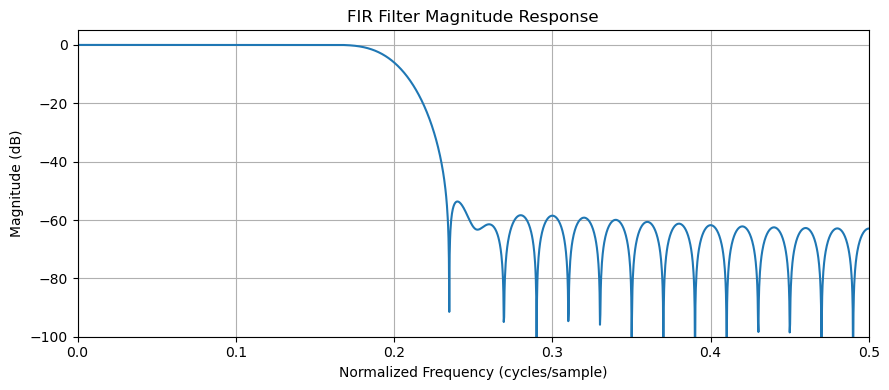

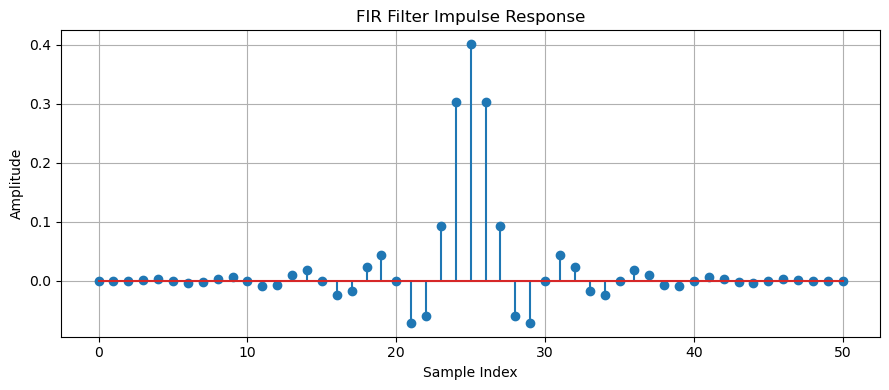

In [26]:
# Design and plot
filter_coefficients = design_fir_filter(
    cutoff_frequency, filter_length, window_type
)

plot_filter_response(filter_coefficients)


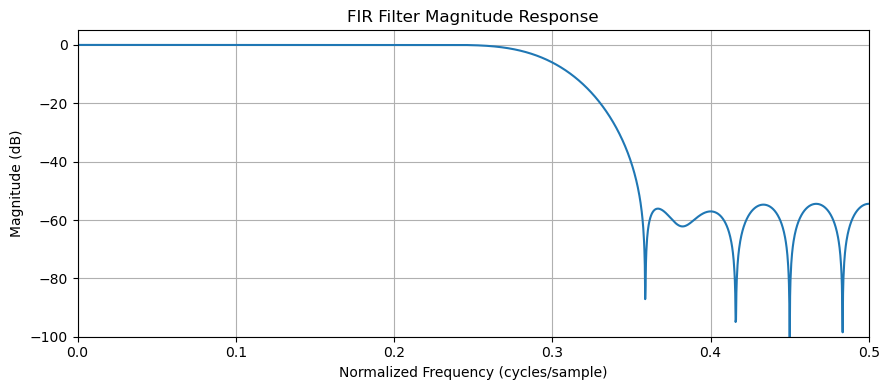

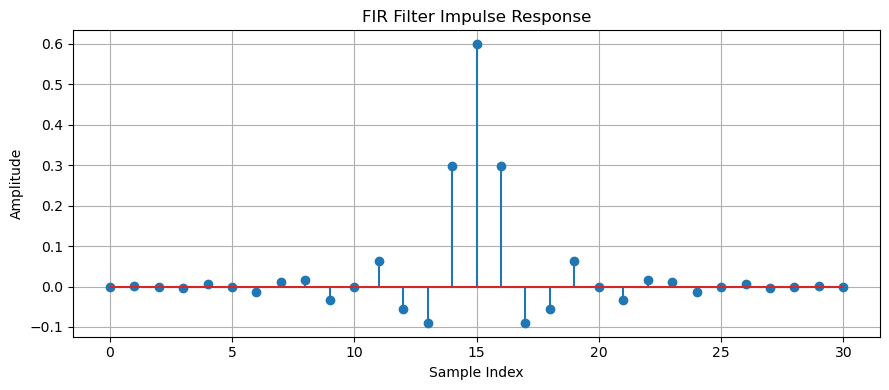

In [27]:
#1. Design FIR Low pass filter having cutoff frequency 3 KHz, N=31; Sampling frequency=10 KHz


# Filter specifications
cutoff_frequency = 3000 / 10000
filter_length = 31
window_type = 'hamming'

filter_coefficients = design_fir_filter(cutoff_frequency, filter_length, window_type)

plot_filter_response(filter_coefficients)

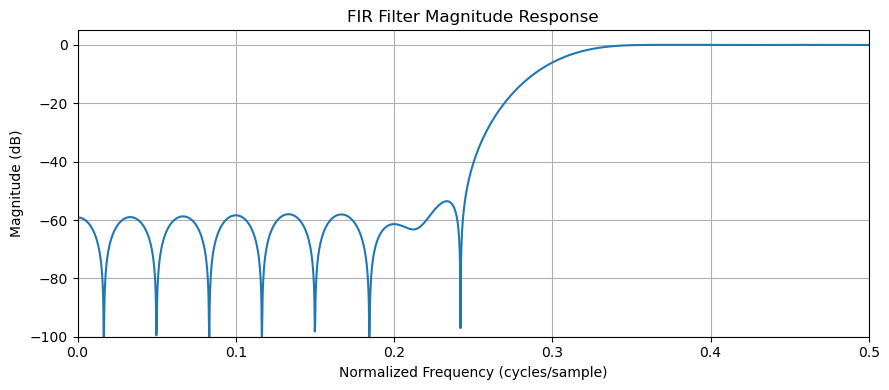

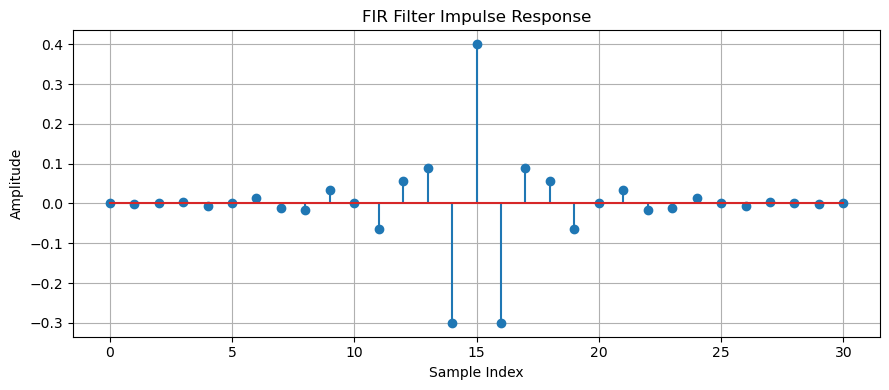

In [29]:
#2. Design FIR High pass filter having cutoff frequency 3 KHz, N=31; Sampling frequency=10 KHz
def design_fir_filter(cutoff_freq, filter_length, window_type='hamming'):

    M = (filter_length - 1) // 2
    n = np.arange(filter_length)

    h_ideal = -2 * cutoff_freq * np.sinc(2 * cutoff_freq * (n - M))

    h_ideal[M] += 1

    if window_type.lower() == 'hamming':
        window = np.hamming(filter_length)
    elif window_type.lower() == 'hanning':
        window = np.hanning(filter_length)
    elif window_type.lower() == 'rectangular':
        window = np.ones(filter_length)
    else:
        raise ValueError("Unsupported window type")

    h = h_ideal * window
    
    return h

cutoff_frequency = 3000 / 10000
filter_length = 31
window_type = 'hamming'

filter_coefficients = design_fir_filter(cutoff_frequency, filter_length, window_type)

plot_filter_response(filter_coefficients)


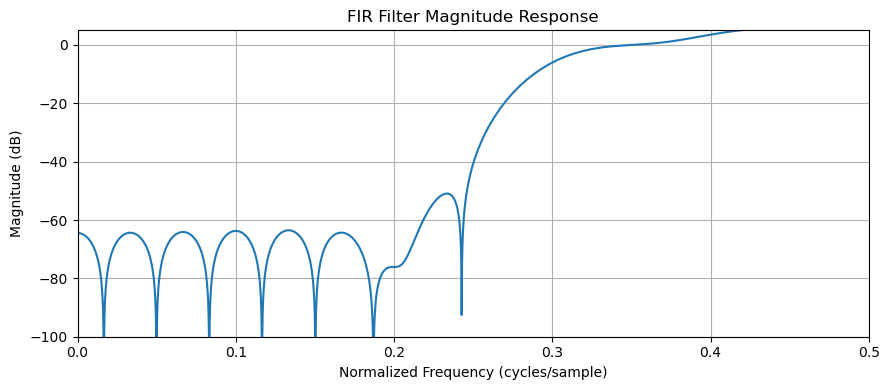

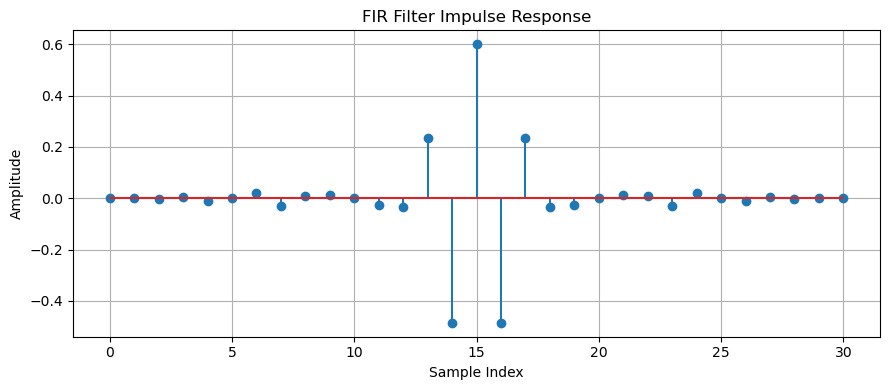

In [32]:
#3. Design FIR Band pass filter having cutoff frequency( 3 KHz, 6 KHz) N=31; Sampling frequency=10 KHz

def design_fir_filter(cutoff_freq1, cutoff_freq2,filter_length, window_type='hamming'):

    M = (filter_length - 1) // 2
    n = np.arange(filter_length)

    # Ideal band-pass FIR impulse response
    h_ideal = (
        2 * cutoff_freq2 * np.sinc(2 * cutoff_freq2 * (n - M))
        - 2 * cutoff_freq1 * np.sinc(2 * cutoff_freq1 * (n - M))
    )

    # Select the window
    if window_type.lower() == 'hamming':
        window = np.hamming(filter_length)
    elif window_type.lower() == 'hanning':
        window = np.hanning(filter_length)
    elif window_type.lower() == 'rectangular':
        window = np.ones(filter_length)
    else:
        raise ValueError("Unsupported window type")

    # Apply window
    h = h_ideal * window

    return h


# Filter specifications
cutoff_frequency1 = 3000 / 10000
cutoff_frequency2 = 6000 / 10000
filter_length = 31
window_type = 'hamming'

# Design and plot
filter_coefficients = design_fir_filter(
    cutoff_frequency1,
    cutoff_frequency2,
    filter_length,
    window_type
)

plot_filter_response(filter_coefficients)

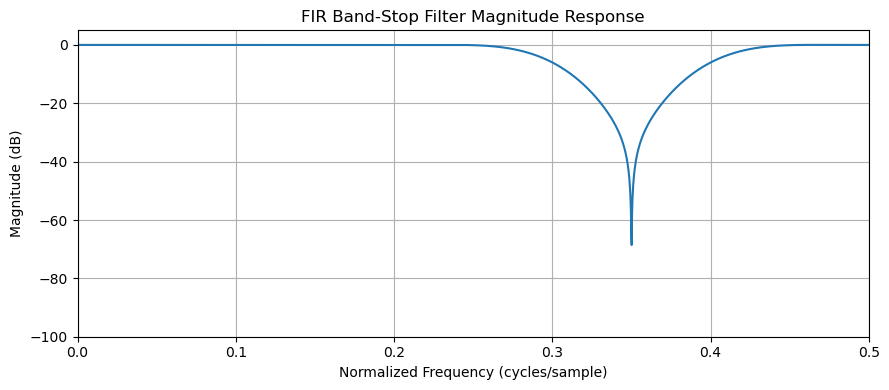

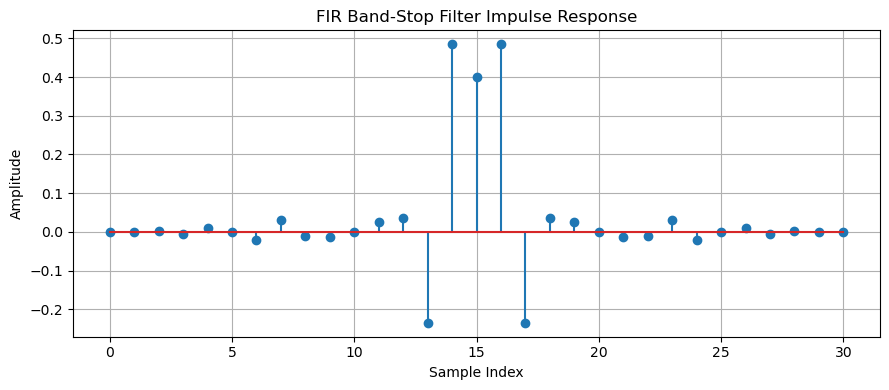

In [34]:
#4. Design FIR Band stop filter having cutoff frequency(3 KHz, 6 KHz) N=31; Sampling frequency=10 KHz

def design_fir_filter(cutoff_freq1, cutoff_freq2,
                      filter_length, window_type='hamming'):

    M = (filter_length - 1) // 2
    n = np.arange(filter_length)

    # Ideal band-stop FIR impulse response
    h_ideal = (
        2 * cutoff_freq1 * np.sinc(2 * cutoff_freq1 * (n - M))
        - 2 * cutoff_freq2 * np.sinc(2 * cutoff_freq2 * (n - M))
    )

    h_ideal[M] += 1

    # Select the window
    if window_type.lower() == 'hamming':
        window = np.hamming(filter_length)
    elif window_type.lower() == 'hanning':
        window = np.hanning(filter_length)
    elif window_type.lower() == 'rectangular':
        window = np.ones(filter_length)
    else:
        raise ValueError("Unsupported window type")

    # Apply window
    h = h_ideal * window

    return h


def plot_filter_response(filter_coefficients):

    N = 4096

    # Frequency response using FFT
    H = np.fft.rfft(filter_coefficients, n=N)
    freq = np.fft.rfftfreq(N, d=1)

    # Magnitude response in dB
    magnitude_db = 20 * np.log10(
        np.maximum(np.abs(H), 1e-10)
    )

    # Plot magnitude response
    plt.figure(figsize=(9, 4))
    plt.plot(freq, magnitude_db)
    plt.title('FIR Band-Stop Filter Magnitude Response')
    plt.xlabel('Normalized Frequency (cycles/sample)')
    plt.ylabel('Magnitude (dB)')
    plt.xlim(0, 0.5)
    plt.ylim(-100, 5)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # Plot impulse response
    plt.figure(figsize=(9, 4))
    plt.stem(np.arange(len(filter_coefficients)),
             filter_coefficients)
    plt.title('FIR Band-Stop Filter Impulse Response')
    plt.xlabel('Sample Index')
    plt.ylabel('Amplitude')
    plt.grid(True)
    plt.tight_layout()
    plt.show()


# Filter specifications
cutoff_frequency1 = 3000 / 10000
cutoff_frequency2 = 6000 / 10000
filter_length = 31
window_type = 'hamming'

# Design and plot
filter_coefficients = design_fir_filter(
    cutoff_frequency1,
    cutoff_frequency2,
    filter_length,
    window_type
)

plot_filter_response(filter_coefficients)


